<a href="https://colab.research.google.com/github/Koushikgmurthy/ML2/blob/main/program_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
!pip install pandas numpy scikit-learn matplotlib seaborn


IRIS DATASET

First 5 rows:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   target species  
0       0  setosa  
1       0  setosa  
2       0  setosa  
3       0  setosa  
4       0  setosa  

Dataset shape:
(150, 6)

Class distribution:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  

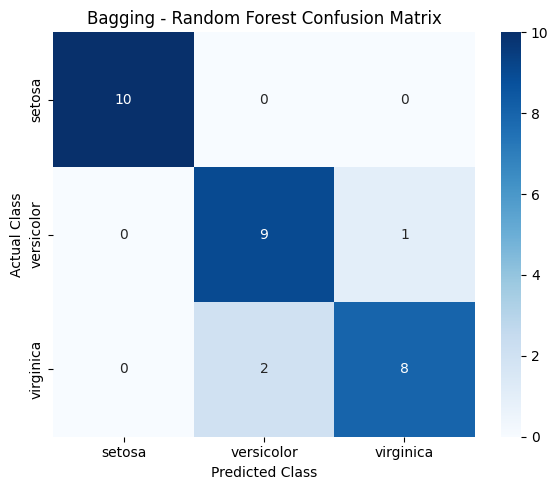

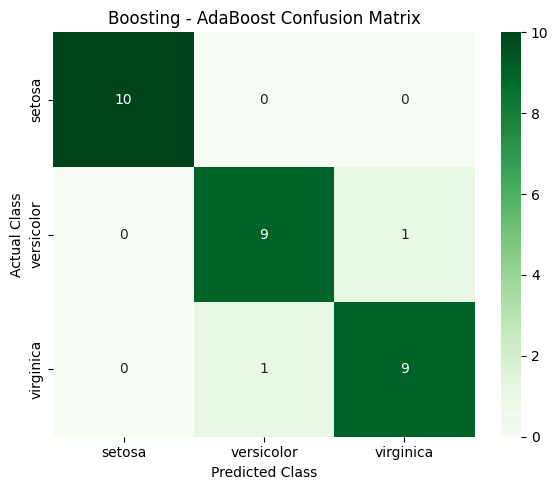

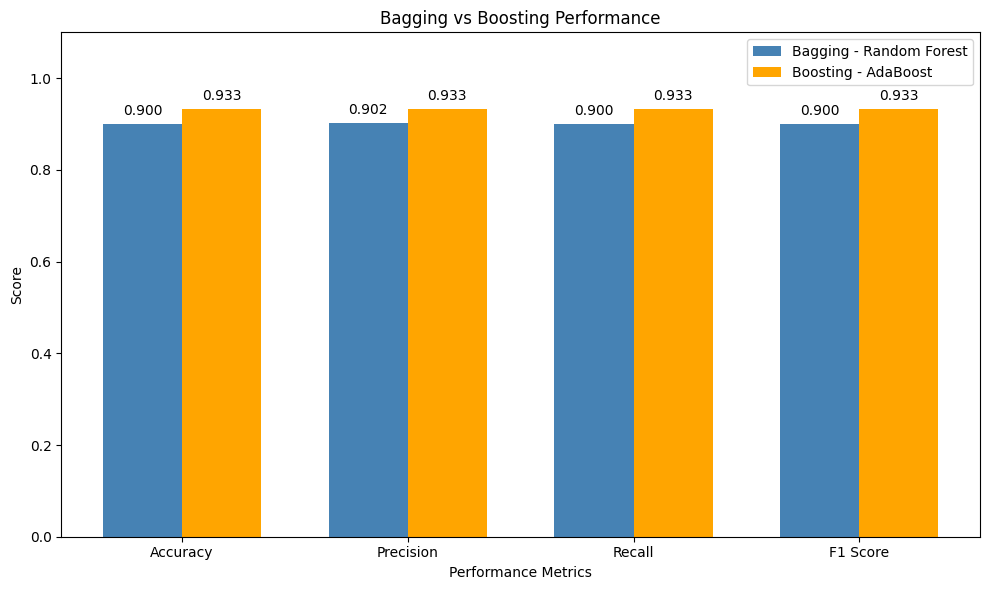

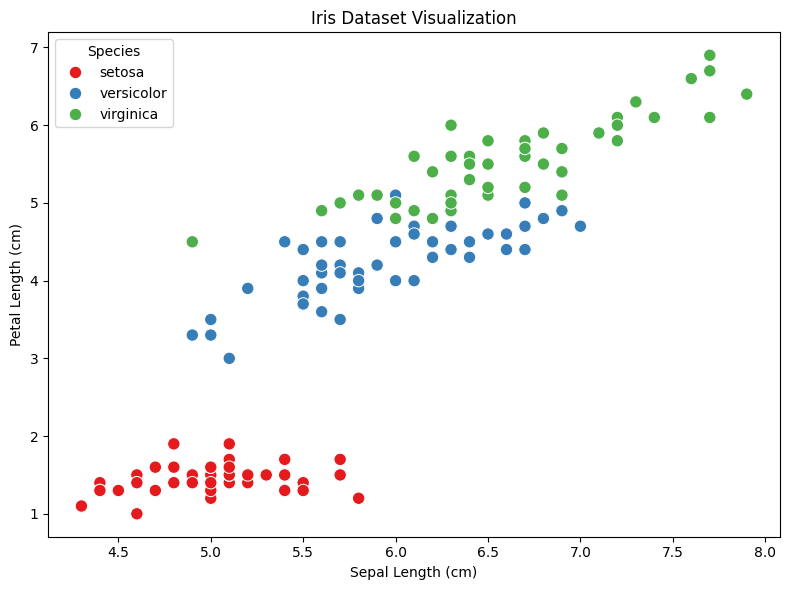


FINAL RESULT
Bagging (Random Forest) Accuracy : 0.9000
Boosting (AdaBoost) Accuracy     : 0.9333

Program completed successfully!


In [3]:
# ============================================================
# BAGGING AND BOOSTING ON IRIS DATASET
# ============================================================

# 1. Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# ------------------------------------------------------------
# 2. Load the Iris supervised dataset
# ------------------------------------------------------------

iris = load_iris()

# Create a DataFrame
df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

# Add target column
df["target"] = iris.target

# Add target names for easier understanding
df["species"] = df["target"].map({
    0: "setosa",
    1: "versicolor",
    2: "virginica"
})

print("=" * 60)
print("IRIS DATASET")
print("=" * 60)

print("\nFirst 5 rows:")
print(df.head())

print("\nDataset shape:")
print(df.shape)

print("\nClass distribution:")
print(df["species"].value_counts())

print("\nDataset information:")
print(df.info())

# ------------------------------------------------------------
# 3. Separate features (X) and target (y)
# ------------------------------------------------------------

X = iris.data
y = iris.target

# ------------------------------------------------------------
# 4. Split dataset into training and testing data
# ------------------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))

# ------------------------------------------------------------
# 5. BAGGING MODEL - Random Forest
# ------------------------------------------------------------

bagging_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

bagging_model.fit(X_train, y_train)

# Predictions
y_pred_bagging = bagging_model.predict(X_test)

# ------------------------------------------------------------
# 6. BOOSTING MODEL - AdaBoost
# ------------------------------------------------------------

boosting_model = AdaBoostClassifier(
    n_estimators=100,
    random_state=42
)

boosting_model.fit(X_train, y_train)

# Predictions
y_pred_boosting = boosting_model.predict(X_test)

# ------------------------------------------------------------
# 7. Calculate performance metrics
# ------------------------------------------------------------

results = []

# Bagging metrics
bagging_accuracy = accuracy_score(y_test, y_pred_bagging)
bagging_precision = precision_score(
    y_test, y_pred_bagging, average="weighted"
)
bagging_recall = recall_score(
    y_test, y_pred_bagging, average="weighted"
)
bagging_f1 = f1_score(
    y_test, y_pred_bagging, average="weighted"
)

results.append([
    "Bagging (Random Forest)",
    bagging_accuracy,
    bagging_precision,
    bagging_recall,
    bagging_f1
])

# Boosting metrics
boosting_accuracy = accuracy_score(y_test, y_pred_boosting)
boosting_precision = precision_score(
    y_test, y_pred_boosting, average="weighted"
)
boosting_recall = recall_score(
    y_test, y_pred_boosting, average="weighted"
)
boosting_f1 = f1_score(
    y_test, y_pred_boosting, average="weighted"
)

results.append([
    "Boosting (AdaBoost)",
    boosting_accuracy,
    boosting_precision,
    boosting_recall,
    boosting_f1
])

# Create comparison DataFrame
results_df = pd.DataFrame(
    results,
    columns=[
        "Model",
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score"
    ]
)

print("\n" + "=" * 60)
print("MODEL PERFORMANCE COMPARISON")
print("=" * 60)

print(results_df.to_string(index=False))

# ------------------------------------------------------------
# 8. Classification reports
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("BAGGING - RANDOM FOREST CLASSIFICATION REPORT")
print("=" * 60)

print(
    classification_report(
        y_test,
        y_pred_bagging,
        target_names=iris.target_names
    )
)

print("\n" + "=" * 60)
print("BOOSTING - ADABOOST CLASSIFICATION REPORT")
print("=" * 60)

print(
    classification_report(
        y_test,
        y_pred_boosting,
        target_names=iris.target_names
    )
)

# ------------------------------------------------------------
# 9. Confusion Matrix - Bagging
# ------------------------------------------------------------

cm_bagging = confusion_matrix(
    y_test,
    y_pred_bagging
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_bagging,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.title("Bagging - Random Forest Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 10. Confusion Matrix - Boosting
# ------------------------------------------------------------

cm_boosting = confusion_matrix(
    y_test,
    y_pred_boosting
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_boosting,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.title("Boosting - AdaBoost Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 11. Compare model performance using bar graph
# ------------------------------------------------------------

metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score"
]

x = np.arange(len(metrics))
width = 0.35

bagging_scores = [
    bagging_accuracy,
    bagging_precision,
    bagging_recall,
    bagging_f1
]

boosting_scores = [
    boosting_accuracy,
    boosting_precision,
    boosting_recall,
    boosting_f1
]

plt.figure(figsize=(10, 6))

bars1 = plt.bar(
    x - width / 2,
    bagging_scores,
    width,
    label="Bagging - Random Forest",
    color="steelblue"
)

bars2 = plt.bar(
    x + width / 2,
    boosting_scores,
    width,
    label="Boosting - AdaBoost",
    color="orange"
)

plt.xlabel("Performance Metrics")
plt.ylabel("Score")
plt.title("Bagging vs Boosting Performance")
plt.xticks(x, metrics)
plt.ylim(0, 1.1)
plt.legend()

# Add values on bars
for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()

        plt.text(
            bar.get_x() + bar.get_width() / 2,
            height + 0.02,
            f"{height:.3f}",
            ha="center",
            fontsize=10
        )

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 12. Dataset visualization
# ------------------------------------------------------------

plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df,
    x="sepal length (cm)",
    y="petal length (cm)",
    hue="species",
    palette="Set1",
    s=80
)

plt.title("Iris Dataset Visualization")
plt.xlabel("Sepal Length (cm)")
plt.ylabel("Petal Length (cm)")
plt.legend(title="Species")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 13. Final comparison
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("FINAL RESULT")
print("=" * 60)

print(
    f"Bagging (Random Forest) Accuracy : "
    f"{bagging_accuracy:.4f}"
)

print(
    f"Boosting (AdaBoost) Accuracy     : "
    f"{boosting_accuracy:.4f}"
)

print("\nProgram completed successfully!")
